<a href="https://colab.research.google.com/github/Sands225/Poultry-Disease-Classification/blob/YOLOv8/%5BBaseline_YOLOv8%5D_Poultry_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline Baseline: Dedup → Split → ROS + Augmentasi → YOLOv11
Urutan kerja (anti data leakage):
1. Validasi label → 2. Hapus duplikat → 3. Split stratified → 4. Balancing train (ROS + augmentasi, pipeline sama untuk semua kelas, **hanya di train**) → 5. Training YOLO11 baseline → 6. Evaluasi di test.

## Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Library Import & Configuration

In [ ]:
import os, re, shutil, random, hashlib, inspect, subprocess, sys
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm

try:
    import albumentations as A
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'albumentations'])
    import albumentations as A
print('albumentations', A.__version__)

albumentations 2.0.8


In [ ]:
SEED        = 42
EXTS        = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
NEAR_THRESH = 4            # jarak hamming dHash untuk "gambar mirip"
NEAR_MODE   = 'group'      # 'group' = near-dup disatukan di split yang sama | 'drop' = near-dup dibuang (sisakan 1)
SPLIT       = (0.70, 0.15, 0.15)   # train / val / test
EXP_NAME    = 'YOLOv8_baseline'    # nama eksperimen (dipakai untuk folder dataset & run training)
TARGET_PER_CLASS = 1600    # target jumlah gambar TRAIN per kelas | None = tanpa balancing (baseline)

# ---- Lokasi input (Drive) ----
BASE       = '/content/drive/MyDrive/College/Deep Learning/Tugas 2/Dataset Zenodo/'
IMG_ROOT   = f'{BASE}/class'                  # class/<kelas>/*.jpg
LABEL_ROOT = f'{BASE}/label_bounding box'     # label_bounding box/<kelas>/*.txt

# ---- Lokasi output ----
OUT        = f'/content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8'
DATA_YAML  = f'{OUT}/data.yaml'
DRIVE_OUT  = f'{BASE}/Output_YOLO'            # semua hasil permanen (Drive)
DRIVE_EXP  = f'{DRIVE_OUT}/{EXP_NAME}'
DRIVE_RUNS = f'{DRIVE_EXP}/runs'
LAPORAN    = f'{DRIVE_EXP}/laporan'
MODEL_NAME = 'yolov8n.pt'                              # 'yolo11n.pt' atau 'yolov8n.pt'
TAG        = os.path.splitext(MODEL_NAME)[0]           # 'yolov8n'
RUN_NAME   = f'{EXP_NAME}_{TAG}'                       # 'ros1600_yolov8n'
RUN        = f'{DRIVE_RUNS}/{RUN_NAME}'
os.makedirs(LAPORAN, exist_ok=True); os.makedirs(DRIVE_RUNS, exist_ok=True)
print("Output permanen →", DRIVE_EXP)

random.seed(SEED); np.random.seed(SEED)

Output permanen → /content/drive/MyDrive/College/Deep Learning/Tugas 2/Dataset Zenodo//Output_YOLO/YOLOv8_baseline


## 2. Cari folder & scan gambar
Menghitung MD5 (duplikat persis) dan dHash (duplikat mirip), sekaligus membuang file korup. Membaca dari Drive, jadi pembacaan pertama bisa memakan beberapa menit.

In [ ]:
assert os.path.isdir(IMG_ROOT), f"Folder gambar tidak ada: {IMG_ROOT}"
assert os.path.isdir(LABEL_ROOT), f"Folder label tidak ada: {LABEL_ROOT}"
IMG_DIR = IMG_ROOT
KELAS = sorted(d for d in os.listdir(IMG_DIR) if os.path.isdir(os.path.join(IMG_DIR, d)))

def cari_induk_kelas(root, kelas):
    """Cari folder (root atau 1+ tingkat di bawahnya) yang berisi semua subfolder kelas."""
    for r, dirs, _ in os.walk(root):
        if all(k in dirs for k in kelas):
            return r

LABEL_DIR = cari_induk_kelas(LABEL_ROOT, KELAS)
assert LABEL_DIR, f"Subfolder label {KELAS} tidak ditemukan di {LABEL_ROOT}"
print("IMG_DIR  :", IMG_DIR)
print("LABEL_DIR:", LABEL_DIR)
print("Kelas    :", {i: k for i, k in enumerate(KELAS)})

def md5(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        while c := f.read(8192):
            h.update(c)
    return h.hexdigest()

rows, korup = [], []
for kelas in KELAS:
    daftar = []
    for root, _, files in os.walk(os.path.join(IMG_DIR, kelas)):
        daftar += [os.path.join(root, f) for f in sorted(files) if f.lower().endswith(EXTS)]
    for p in tqdm(daftar, desc=kelas):
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                w, h = im.size
                g = np.array(im.convert('L'))
            s = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA)
            rows.append(dict(kelas=kelas, path=p, stem=os.path.splitext(os.path.basename(p))[0],
                             w=w, h=h, md5=md5(p), dhash=(s[:, 1:] > s[:, :-1]).flatten()))
        except Exception as e:
            korup.append((kelas, p, str(e)))

df = pd.DataFrame(rows)
print(f"\nGambar terbaca: {len(df)} | Korup (dibuang): {len(korup)}")
display(df.groupby('kelas').size().rename('jumlah').to_frame())

IMG_DIR  : /content/drive/MyDrive/College/Deep Learning/Tugas 2/Dataset Zenodo//class
LABEL_DIR: /content/drive/MyDrive/College/Deep Learning/Tugas 2/Dataset Zenodo//label_bounding box
Kelas    : {0: 'cocci', 1: 'healthy', 2: 'ncd', 3: 'salmo'}


cocci:   0%|          | 0/2103 [00:00<?, ?it/s]

healthy:   0%|          | 0/2058 [00:00<?, ?it/s]

ncd:   0%|          | 0/376 [00:00<?, ?it/s]

salmo:   0%|          | 0/2275 [00:00<?, ?it/s]


Gambar terbaca: 6812 | Korup (dibuang): 0


,jumlah
kelas,
cocci,2103
healthy,2058
ncd,376
salmo,2275


## 3. Validasi label
Gambar dibuang jika labelnya hilang, kosong, atau formatnya rusak. Box yang sedikit keluar batas (0–1) di-*clip*.

In [ ]:
label_idx = {}
for kelas in KELAS:
    for root, _, files in os.walk(os.path.join(LABEL_DIR, kelas)):
        for f in files:
            if f.lower().endswith('.txt'):
                label_idx[(kelas, os.path.splitext(f)[0])] = os.path.join(root, f)

def baca_label(path):
    """Return (boxes[(cid,x,y,w,h)], alasan_gagal)."""
    with open(path) as f:
        lines = [l.split() for l in f if l.strip()]
    if not lines:
        return [], 'label kosong'
    boxes = []
    for p in lines:
        if len(p) != 5:
            return [], 'format salah'
        try:
            c = int(float(p[0])); x, y, w, h = map(float, p[1:])
        except ValueError:
            return [], 'nilai bukan angka'
        x1, x2 = max(x - w/2, 0.0), min(x + w/2, 1.0)
        y1, y2 = max(y - h/2, 0.0), min(y + h/2, 1.0)
        if x2 - x1 <= 1e-3 or y2 - y1 <= 1e-3:
            return [], 'box tidak valid'
        boxes.append((c, (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1))
    return boxes, None

boxes_list, alasan = [], []
for r in df.itertuples():
    p = label_idx.get((r.kelas, r.stem))
    if p is None:
        boxes_list.append(None); alasan.append('label hilang'); continue
    b, a = baca_label(p)
    boxes_list.append(b if a is None else None); alasan.append(a)

df['boxes'] = boxes_list
df['alasan'] = alasan
df['label_ok'] = df.alasan.isna()

print(f"Label valid: {df.label_ok.sum()} dari {len(df)} gambar")
if (~df.label_ok).any():
    display(df[~df.label_ok].groupby(['alasan', 'kelas']).size().unstack('kelas', fill_value=0))

# Cek konsistensi class ID di file label vs folder (informasi saja)
ID_FOLDER = {k: i for i, k in enumerate(KELAS)}
beda = [(r.kelas, r.stem) for r in df[df.label_ok].itertuples()
        if any(c != ID_FOLDER[r.kelas] for c, *_ in r.boxes)]
print(f"\nClass ID di file label ≠ urutan folder alfabetis: {len(beda)} gambar")
print("Class ID akan di-set ulang mengikuti folder:", ID_FOLDER)

Label valid: 6803 dari 6812 gambar


kelas,cocci,healthy,salmo
alasan,,,
box tidak valid,5,0,0
label hilang,0,1,0
label kosong,1,0,2



Class ID di file label ≠ urutan folder alfabetis: 4967 gambar
Class ID akan di-set ulang mengikuti folder: {'cocci': 0, 'healthy': 1, 'ncd': 2, 'salmo': 3}


## 4. Hapus duplikat persis (MD5)
- Duplikat dalam satu kelas → sisakan 1 (prioritas: label valid, lalu nama file terpendek).
- Duplikat **antar kelas** → buang semua anggotanya (labelnya ambigu).

In [ ]:
buang = set(); n_lintas = 0
for h, idx in df.groupby('md5').indices.items():
    if len(idx) < 2:
        continue
    if df.kelas.iloc[idx].nunique() > 1:
        buang.update(idx); n_lintas += 1
    else:
        urut = sorted(idx, key=lambda i: (not df.label_ok.iloc[i], len(df.path.iloc[i]), df.path.iloc[i]))
        buang.update(urut[1:])

df['keep_exact'] = ~df.index.isin(list(buang))
print(f"Grup duplikat antar kelas (dibuang semua): {n_lintas}")
print(f"Gambar duplikat persis dibuang: {len(buang)}")
display(df.assign(dibuang=~df.keep_exact).groupby('kelas').dibuang.sum().rename('dibuang').to_frame())

Grup duplikat antar kelas (dibuang semua): 0
Gambar duplikat persis dibuang: 319


,dibuang
kelas,
cocci,133
healthy,4
ncd,2
salmo,180


## 5. Duplikat mirip (dHash)
- Mirip **antar kelas** → buang (label ambigu).
- Mirip dalam satu kelas → dikelompokkan jadi satu *group*. Dengan `NEAR_MODE='group'`, satu group tidak akan terpecah ke train/val/test (mencegah leakage tanpa membuang data). Dengan `'drop'`, hanya 1 anggota per group yang disimpan.

In [ ]:
cand = df[df.keep_exact & df.label_ok].copy()
cand['orig'] = cand.index
cand = cand.reset_index(drop=True)
cand_all = cand.copy()
Hm = np.stack(cand.dhash.values).astype(np.float32)
Dm = 64 - (Hm @ Hm.T + (1 - Hm) @ (1 - Hm).T)
ii, jj = np.where(np.triu(Dm <= NEAR_THRESH, 1))
del Hm, Dm

kel = cand.kelas.values
lintas = {int(i) for i, j in zip(ii, jj) if kel[i] != kel[j]} | {int(j) for i, j in zip(ii, jj) if kel[i] != kel[j]}

parent = list(range(len(cand)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for i, j in zip(ii, jj):
    if int(i) in lintas or int(j) in lintas:
        continue
    ri, rj = find(int(i)), find(int(j))
    if ri != rj:
        parent[rj] = ri
cand['group'] = [find(i) for i in range(len(cand))]

cand = cand.drop(index=sorted(lintas))
ukuran = cand.groupby('group').size()
print(f"Pasangan mirip: {len(ii)} | Gambar mirip antar kelas (dibuang): {len(lintas)}")
print(f"Group dengan >1 anggota: {(ukuran > 1).sum()} | Ukuran group terbesar: {ukuran.max()}")

if NEAR_MODE == 'drop':
    cand['_len'] = cand.path.str.len()
    cand = cand.sort_values(['group', '_len', 'path']).drop_duplicates('group').drop(columns='_len')

final = cand.reset_index(drop=True)
print(f"\nGambar final setelah dedup: {len(final)}")
display(final.groupby('kelas').size().rename('jumlah').to_frame())

# Status tiap gambar (untuk laporan di Drive)
lintas_orig = set(cand_all.orig.iloc[sorted(lintas)]) if lintas else set()
final_orig = set(final.orig)
status = []
for r in df.itertuples():
    if not r.keep_exact:
        status.append('duplikat persis (dibuang)')
    elif not r.label_ok:
        status.append(f'label bermasalah: {r.alasan}')
    elif r.Index in lintas_orig:
        status.append('mirip antar kelas (dibuang)')
    elif r.Index not in final_orig:
        status.append('mirip dalam kelas (dibuang, mode drop)')
    else:
        status.append('dipakai')
df['status'] = status
print("\nRingkasan status semua gambar:")
display(df.groupby(['status', 'kelas']).size().unstack('kelas', fill_value=0))

Pasangan mirip: 307 | Gambar mirip antar kelas (dibuang): 6
Group dengan >1 anggota: 11 | Ukuran group terbesar: 43

Gambar final setelah dedup: 6479


,jumlah
kelas,
cocci,1963
healthy,2051
ncd,373
salmo,2092



Ringkasan status semua gambar:


kelas,cocci,healthy,ncd,salmo
status,,,,
dipakai,1963,2051,373,2092
duplikat persis (dibuang),133,4,2,180
label bermasalah: box tidak valid,5,0,0,0
label bermasalah: label kosong,1,0,0,2
mirip antar kelas (dibuang),1,3,1,1


## 6. Split train / val / test (stratified per kelas, group-aware)

In [ ]:
NAMA_SPLIT = ['train', 'val', 'test']
meta = final.copy()
meta['split'] = ''

for kelas in KELAS:
    sub = meta[meta.kelas == kelas]
    gsize = sub.groupby('group').size()
    groups = list(gsize.index); random.shuffle(groups)
    groups.sort(key=lambda g: -gsize[g])           # group besar dulu, supaya proporsi pas
    target = [len(sub) * r for r in SPLIT]; cur = [0, 0, 0]; assign = {}
    for g in groups:
        s = int(np.argmax([target[k] - cur[k] for k in range(3)]))
        cur[s] += gsize[g]; assign[g] = NAMA_SPLIT[s]
    meta.loc[sub.index, 'split'] = sub.group.map(assign)

tab = pd.crosstab(meta.kelas, meta.split)[NAMA_SPLIT]
tab['total'] = tab.sum(axis=1)
display(tab)
display((pd.crosstab(meta.kelas, meta.split, normalize='index')[NAMA_SPLIT] * 100).round(1))

split,train,val,test,total
kelas,,,,
cocci,1374,295,294,1963
healthy,1436,308,307,2051
ncd,261,56,56,373
salmo,1464,314,314,2092


split,train,val,test
kelas,,,
cocci,70.0,15.0,15.0
healthy,70.0,15.0,15.0
ncd,70.0,15.0,15.0
salmo,70.0,15.0,15.0


## 7. Tulis dataset ke format YOLO
Struktur: `yolo_ds/images/{train,val,test}` dan `yolo_ds/labels/{train,val,test}`. Class ID mengikuti urutan folder.

In [ ]:
if os.path.exists(OUT):
    shutil.rmtree(OUT)
for s in NAMA_SPLIT:
    os.makedirs(f'{OUT}/images/{s}'); os.makedirs(f'{OUT}/labels/{s}')

used, out_names = set(), []
for r in tqdm(meta.itertuples(), total=len(meta)):
    ext = os.path.splitext(r.path)[1].lower()
    base = f"{r.kelas}_{re.sub(r'[^A-Za-z0-9_.-]', '_', r.stem)}"
    while base in used:
        base += '_x'
    used.add(base)
    shutil.copy2(r.path, f'{OUT}/images/{r.split}/{base}{ext}')
    with open(f'{OUT}/labels/{r.split}/{base}.txt', 'w') as f:
        for _, x, y, w, h in r.boxes:
            f.write(f"{ID_FOLDER[r.kelas]} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")
    out_names.append(base + ext)
meta['out_name'] = out_names
print("Selesai menulis", len(meta), "gambar ke", OUT)

  0%|          | 0/6479 [00:00<?, ?it/s]

Selesai menulis 6479 gambar ke /content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8


## 8. Hitung distribusi (fungsi bantu)

In [ ]:
def hitung():
    rows = []
    for s in NAMA_SPLIT:
        for fn in os.listdir(f'{OUT}/labels/{s}'):
            with open(f'{OUT}/labels/{s}/{fn}') as f:
                lines = [l.split() for l in f if l.strip()]
            if lines:
                rows.append((s, KELAS[int(lines[0][0])], 'aug' if '__aug' in fn else 'asli', len(lines)))
    t = pd.DataFrame(rows, columns=['split', 'kelas', 'tipe', 'bbox'])
    g = t.groupby(['kelas', 'split']).size().unstack('split', fill_value=0)[NAMA_SPLIT]
    g['total'] = g.sum(axis=1)
    return g, t

g_awal, _ = hitung()
print("Jumlah gambar per kelas dan split (sebelum ROS):")
display(g_awal)

Jumlah gambar per kelas dan split (sebelum ROS):


split,train,val,test,total
kelas,,,,
cocci,1374,295,294,1963
healthy,1436,308,307,2051
ncd,261,56,56,373
salmo,1464,314,314,2092


## 9. Pipeline augmentasi geometris (dengan bbox)
Hanya transformasi geometris (flip, rotate 90°, rotate kecil, scale, translate). Tidak ada perubahan warna. Tepi kosong hasil rotasi/geser diisi dengan memperpanjang piksel tepi (`BORDER_REPLICATE`), bukan warna hitam, supaya tidak jadi "ciri" kelas NCD. Mode *reflect* sengaja tidak dipakai karena Albumentations 2.x menambahkan box "pantulan" untuk objek yang menempel di tepi gambar.

In [ ]:
def buat_affine():
    kw = dict(scale=(0.85, 1.15), translate_percent=(-0.08, 0.08), rotate=(-15, 15), p=0.8)
    params = inspect.signature(A.Affine.__init__).parameters
    key = 'border_mode' if 'border_mode' in params else 'mode'
    return A.Affine(**kw, **{key: cv2.BORDER_REPLICATE})

pipeline = A.Compose(
    [A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5), buat_affine()],
    bbox_params=A.BboxParams(format='yolo', label_fields=['class_ids'], min_visibility=0.4),
)

def augment_once(img, boxes):
    """img: BGR. boxes: [(cid,x,y,w,h)]. Return (img, [(x,y,w,h)]) atau None bila semua box hilang."""
    bb = [[round(x, 6), round(y, 6), round(w, 6), round(h, 6)] for _, x, y, w, h in boxes]
    try:
        o = pipeline(image=img, bboxes=bb, class_ids=[0] * len(bb))
    except ValueError:
        return None
    if len(o['bboxes']) == 0:
        return None
    return o['image'], [tuple(b) for b in o['bboxes']]

print("Pipeline siap:", [type(t).__name__ for t in pipeline.transforms])

Pipeline siap: ['HorizontalFlip', 'VerticalFlip', 'RandomRotate90', 'Affine']


## 10. Cek visual hasil augmentasi (semua kelas)
Tiap baris = satu kelas. Kolom pertama asli, tiga kolom berikutnya hasil augmentasi dari gambar yang sama. Pastikan kotak merah tetap menempel pada objek.

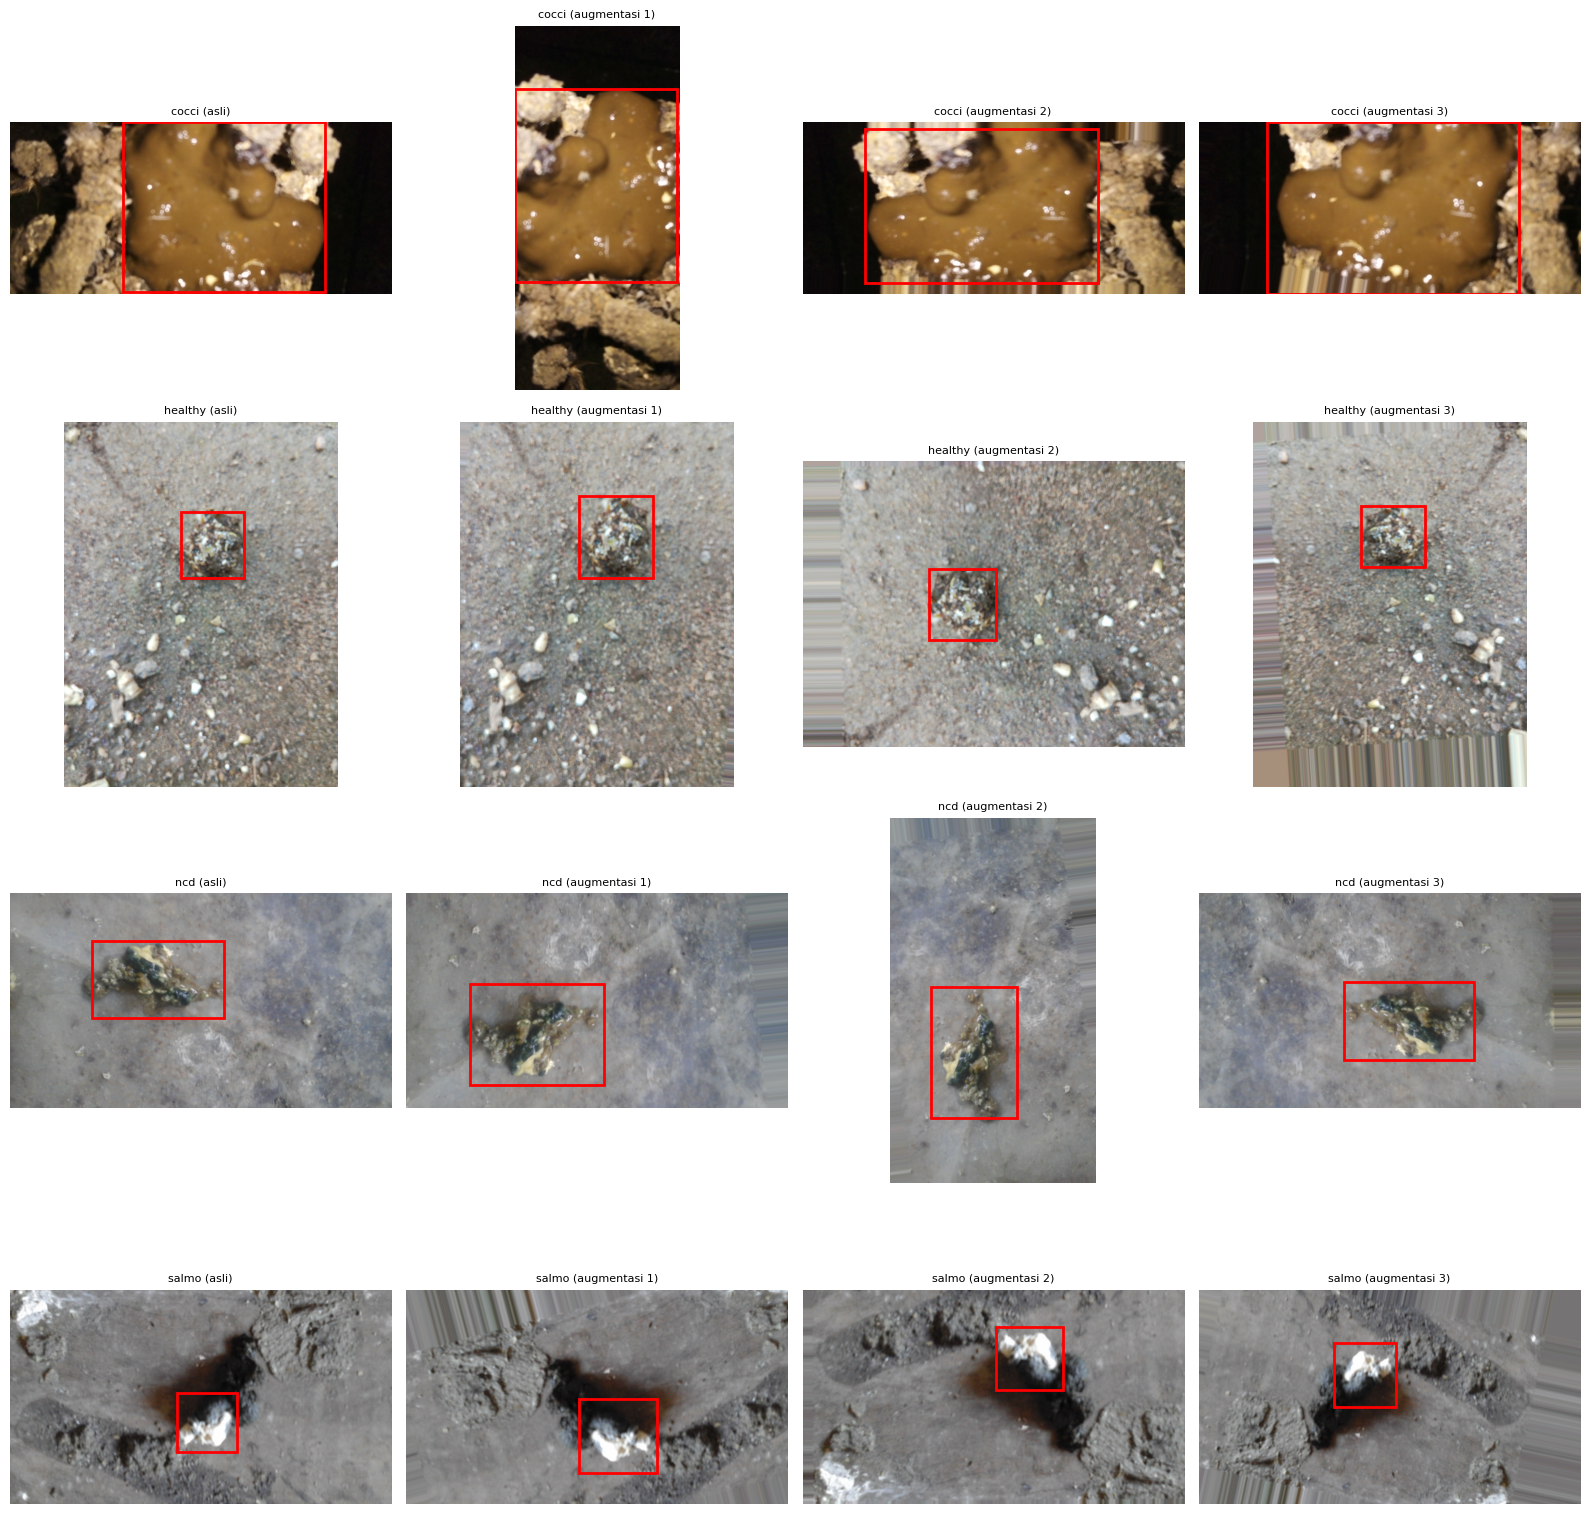

In [ ]:
def gambar_box(ax, img_bgr, boxes_xywh, judul=''):
    H_, W_ = img_bgr.shape[:2]
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    for x, y, w, h in boxes_xywh:
        ax.add_patch(patches.Rectangle(((x - w/2) * W_, (y - h/2) * H_), w * W_, h * H_,
                                       fill=False, edgecolor='red', linewidth=2))
    ax.set_title(judul, fontsize=8); ax.axis('off')

fig, axes = plt.subplots(len(KELAS), 4, figsize=(16, 4 * len(KELAS)))
for row, kelas in enumerate(KELAS):
    sk = meta[(meta.split == 'train') & (meta.kelas == kelas)].reset_index(drop=True)
    r = sk.iloc[random.randrange(len(sk))]
    img = cv2.imread(f'{OUT}/images/train/{r.out_name}')
    gambar_box(axes[row, 0], img, [b[1:] for b in r.boxes], f'{kelas} (asli)')
    for col in (1, 2, 3):
        res = None
        for _ in range(10):
            res = augment_once(img, r.boxes)
            if res: break
        if res:
            gambar_box(axes[row, col], res[0], res[1], f'{kelas} (augmentasi {col})')
        else:
            axes[row, col].axis('off')
plt.tight_layout(); plt.show()

## 11. Balancing train: ROS + augmentasi untuk semua kelas
Tiap kelas di train yang jumlahnya di bawah `TARGET_PER_CLASS` ditambah salinan augmentasi sampai target. Kelas yang sudah ≥ target dibiarkan apa adanya (tanpa undersampling). Gambar sumber dipakai **bergilir** (acak urutannya, lalu diulang) sehingga tiap gambar asli terpakai sama rata, bukan acak dengan pengembalian.

In [ ]:
random.seed(SEED); np.random.seed(SEED)
if not TARGET_PER_CLASS:
    print("TARGET_PER_CLASS = None → tanpa balancing (baseline murni).")

train_meta = meta[meta.split == 'train']
diag = []
for kelas in KELAS:
    sk = train_meta[train_meta.kelas == kelas].reset_index(drop=True)
    n_asli = len(sk)
    extra = max(0, TARGET_PER_CLASS - n_asli) if TARGET_PER_CLASS else 0
    pakai = np.zeros(n_asli, dtype=int)
    order, pos, made, tries = [], 0, 0, 0
    pbar = tqdm(total=extra, desc=kelas)
    while made < extra and tries < extra * 10:
        tries += 1
        if pos >= len(order):
            order = list(range(n_asli)); random.shuffle(order); pos = 0
        i = order[pos]; pos += 1
        r = sk.iloc[i]
        img = cv2.imread(f'{OUT}/images/train/{r.out_name}')
        res = augment_once(img, r.boxes)
        if res is None:
            continue
        aimg, abox = res
        base, ext = os.path.splitext(r.out_name)
        nama = f'{base}__aug{made}'
        cv2.imwrite(f'{OUT}/images/train/{nama}{ext}', aimg, [cv2.IMWRITE_JPEG_QUALITY, 95])
        with open(f'{OUT}/labels/train/{nama}.txt', 'w') as f:
            for x, y, w, h in abox:
                f.write(f"{ID_FOLDER[kelas]} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")
        pakai[i] += 1; made += 1; pbar.update(1)
    pbar.close()
    diag.append(dict(kelas=kelas, asli=n_asli, salinan=made, total_train=n_asli + made,
                     rasio_per_gambar=round(made / n_asli, 1),
                     persen_augmentasi=round(100 * made / (n_asli + made), 1),
                     pakai_maks_per_gambar=int(pakai.max())))

diag = pd.DataFrame(diag).set_index('kelas')
print("\nDiagnostik duplikasi:")
display(diag)
for k, r in diag.iterrows():
    if r.rasio_per_gambar > 8:
        print(f"⚠️ {k}: tiap gambar asli diduplikasi ~{r.rasio_per_gambar}x. Risiko menghafal, pertimbangkan TARGET_PER_CLASS lebih kecil.")

cocci:   0%|          | 0/226 [00:00<?, ?it/s]

healthy:   0%|          | 0/164 [00:00<?, ?it/s]

ncd:   0%|          | 0/1339 [00:00<?, ?it/s]

salmo:   0%|          | 0/136 [00:00<?, ?it/s]


Diagnostik duplikasi:


,asli,salinan,total_train,rasio_per_gambar,persen_augmentasi,pakai_maks_per_gambar
kelas,,,,,,
cocci,1374,226,1600,0.2,14.1,1
healthy,1436,164,1600,0.1,10.2,1
ncd,261,1339,1600,5.1,83.7,6
salmo,1464,136,1600,0.1,8.5,1


## 12. Distribusi akhir

Jumlah gambar per kelas dan split (setelah ROS):


split,train,val,test,total
kelas,,,,
cocci,1600,295,294,2189
healthy,1600,308,307,2215
ncd,1600,56,56,1712
salmo,1600,314,314,2228



Komposisi train (asli vs augmentasi):


tipe,asli,aug
kelas,,
cocci,1374,226
healthy,1436,164
ncd,261,1339
salmo,1464,136



Jumlah bbox per kelas dan split:


split,train,val,test
kelas,,,
cocci,2328,423,416
healthy,2580,491,500
ncd,1624,59,57
salmo,1636,320,322


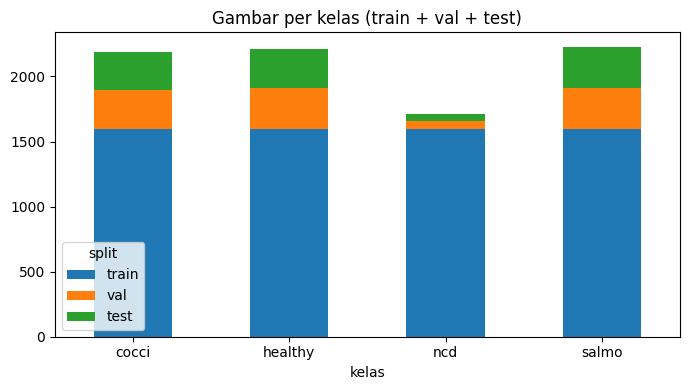

In [ ]:
g_akhir, t_akhir = hitung()
print("Jumlah gambar per kelas dan split (setelah ROS):")
display(g_akhir)
print("\nKomposisi train (asli vs augmentasi):")
display(t_akhir[t_akhir.split == 'train'].groupby(['kelas', 'tipe']).size().unstack('tipe', fill_value=0))
print("\nJumlah bbox per kelas dan split:")
display(t_akhir.groupby(['kelas', 'split']).bbox.sum().unstack('split', fill_value=0)[NAMA_SPLIT])

g_akhir[NAMA_SPLIT].plot(kind='bar', stacked=True, figsize=(7, 4), rot=0)
plt.title('Gambar per kelas (train + val + test)'); plt.tight_layout(); plt.show()

## 13. Buat `data.yaml`

In [ ]:
yaml_text = (f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
             + ''.join(f"  {i}: {k}\n" for i, k in enumerate(KELAS)))
with open(DATA_YAML, 'w') as f:
    f.write(yaml_text)
print(yaml_text)

path: /content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8
train: images/train
val: images/val
test: images/test
names:
  0: cocci
  1: healthy
  2: ncd
  3: salmo



## 14. Simpan dataset & laporan ke Drive
Dataset kerja ada di disk lokal Colab (hilang kalau runtime reset), jadi di-zip ke Drive. Laporan CSV (status tiap gambar, manifest split, diagnostik balancing, distribusi) juga disimpan di sini.

In [ ]:
df[['kelas', 'path', 'stem', 'w', 'h', 'md5', 'label_ok', 'alasan', 'keep_exact', 'status']].to_csv(f'{LAPORAN}/status_semua_gambar.csv', index=False)
meta[['kelas', 'path', 'out_name', 'split', 'group']].to_csv(f'{LAPORAN}/manifest_split.csv', index=False)
diag.to_csv(f'{LAPORAN}/diagnostik_balancing.csv')
g_akhir.to_csv(f'{LAPORAN}/distribusi_akhir.csv')
pd.DataFrame(korup, columns=['kelas', 'path', 'error']).to_csv(f'{LAPORAN}/file_korup.csv', index=False)
print("Laporan tersimpan di:", LAPORAN, "→", sorted(os.listdir(LAPORAN)))

ZIP_BASE = f'{DRIVE_EXP}/yolo_ds_{EXP_NAME}'
if os.path.exists(ZIP_BASE + '.zip'):
    os.remove(ZIP_BASE + '.zip')
shutil.make_archive(ZIP_BASE, 'zip', root_dir=os.path.dirname(OUT), base_dir=os.path.basename(OUT))
print(f"Dataset di-zip ke Drive: {ZIP_BASE}.zip ({os.path.getsize(ZIP_BASE + '.zip') / 1e6:.0f} MB)")

Laporan tersimpan di: /content/drive/MyDrive/College/Deep Learning/Tugas 2/Dataset Zenodo//Output_YOLO/YOLOv8_baseline/laporan → ['diagnostik_balancing.csv', 'distribusi_akhir.csv', 'file_korup.csv', 'manifest_split.csv', 'status_semua_gambar.csv']
Dataset di-zip ke Drive: /content/drive/MyDrive/College/Deep Learning/Tugas 2/Dataset Zenodo//Output_YOLO/YOLOv8_baseline/yolo_ds_YOLOv8_baseline.zip (9484 MB)


## 15. (Opsional) Pulihkan dataset dari Drive
Pakai sel ini kalau runtime Colab ter-reset setelah bagian 14. Cukup jalankan bagian 0, 1, sel ini, lalu lompat ke bagian 16 (training), tanpa mengulang preprocessing. `EXP_NAME` harus sama dengan saat dataset dibuat.

In [ ]:
if os.path.exists(DATA_YAML):
    print("Dataset lokal sudah ada:", OUT)
else:
    z = f'{DRIVE_EXP}/yolo_ds_{EXP_NAME}.zip'
    assert os.path.exists(z), f"Zip tidak ada di Drive ({z}). Jalankan ulang bagian 2-14."
    shutil.unpack_archive(z, os.path.dirname(OUT))
    print("Dataset dipulihkan ke", OUT)

Dataset lokal sudah ada: /content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8


## 16. Training baseline YOLO11n
Model paling kecil (`yolo11n`) dengan pengaturan default, sebagai pembanding awal. Augmentasi online bawaan Ultralytics (mosaic, flip, HSV) tetap aktif dan berlaku untuk semua kelas.
Bobot dan kurva langsung ditulis ke Drive (`RUN`), jadi aman kalau runtime putus. Kalau training terputus, jalankan sel berikutnya (bagian 16b) untuk melanjutkan.

In [ ]:
os.environ['WANDB_DISABLED'] = 'true'
try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])
    from ultralytics import YOLO

model = YOLO(MODEL_NAME)
results = model.train(
    data=DATA_YAML, epochs=50, imgsz=640, batch=16, patience=15,
    seed=SEED, workers=2, plots=True,
    project=DRIVE_RUNS, name=RUN_NAME, exist_ok=True,
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8_baselin

KeyboardInterrupt: 

## 16b. (Opsional) Lanjutkan training yang terputus
Jalankan hanya jika training berhenti di tengah jalan (runtime putus). Lewati bagian 16 dan lanjut dari checkpoint terakhir.

In [ ]:
# model = YOLO(f'{RUN}/weights/last.pt')
# results = model.train(resume=True)

## 17. Kurva training

In [ ]:
plt.figure(figsize=(14, 8))
plt.imshow(Image.open(f'{RUN}/results.png')); plt.axis('off'); plt.show()

## 18. Evaluasi di test set (bobot terbaik)

In [ ]:
best = YOLO(f'{RUN}/weights/best.pt')
m = best.val(data=DATA_YAML, split='test', project=DRIVE_RUNS, name=f'{RUN_NAME}_test', exist_ok=True)

print(f"\nmAP50: {m.box.map50:.3f} | mAP50-95: {m.box.map:.3f} | P: {m.box.mp:.3f} | R: {m.box.mr:.3f}")
rows = []
for i, ci in enumerate(m.box.ap_class_index):
    p, r_, ap50, ap = m.box.class_result(i)
    rows.append((m.names[int(ci)], p, r_, ap50, ap))
display(pd.DataFrame(rows, columns=['kelas', 'precision', 'recall', 'mAP50', 'mAP50-95']).set_index('kelas').round(3))

## 19. Simpan metrik & bandingkan antar eksperimen
Hasil tiap `EXP_NAME` ditambahkan ke satu CSV. Jalankan notebook lagi dengan `EXP_NAME`/`TARGET_PER_CLASS` lain, lalu tabel ini otomatis membandingkan semuanya. File CSV ada di Drive (`Output_YOLO/hasil_eksperimen.csv`), jadi hasilnya tetap ada lintas sesi.

In [ ]:
CSV_HASIL = f'{DRIVE_OUT}/hasil_eksperimen.csv'
baris = [(RUN_NAME, 'ALL', m.box.mp, m.box.mr, m.box.map50, m.box.map)]
for i, ci in enumerate(m.box.ap_class_index):
    p, r_, ap50, ap = m.box.class_result(i)
    baris.append((RUN_NAME, m.names[int(ci)], p, r_, ap50, ap))
baru = pd.DataFrame(baris, columns=['exp', 'kelas', 'precision', 'recall', 'mAP50', 'mAP50-95'])
if os.path.exists(CSV_HASIL):
    lama = pd.read_csv(CSV_HASIL)
    baru = pd.concat([lama[lama.exp != RUN_NAME], baru], ignore_index=True)
baru.to_csv(CSV_HASIL, index=False)
for metrik in ['recall', 'mAP50-95']:
    print(f"\n{metrik} per kelas, per eksperimen:")
    display(baru.pivot(index='kelas', columns='exp', values=metrik).round(3))

## 20. Confusion matrix

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, fn in zip(ax, ['confusion_matrix.png', 'confusion_matrix_normalized.png']):
    a.imshow(Image.open(f'{m.save_dir}/{fn}')); a.axis('off')
plt.tight_layout(); plt.show()

## 21. Contoh prediksi di test set

In [ ]:
test_imgs = [f'{OUT}/images/test/{f}' for f in os.listdir(f'{OUT}/images/test')]
sampel = random.sample(test_imgs, min(8, len(test_imgs)))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axes.flat, sampel):
    r_ = best.predict(p, conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r_.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(p), fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()